# Food.com token map and collaborative-filtering experiment

## tl;dr

The dataset contains 178,265 tokenized recipes and 718,379 supplied split interactions from 25,076 users. The matrix is 99.984% sparse and ratings are strongly positive-skewed. The supplied validation/test files are cold-recipe generation splits (zero item overlap with train), so this notebook uses the reproducible chronological per-user split generated from `RAW_interactions.csv`. On 6,000 held-out positive queries with 99 sampled unseen negatives each, the 75% BPR + 25% ingredient-profile hybrid improves HR@10 from 0.6393 (popularity) to 0.6547 and nDCG@10 from 0.4573 to 0.4670. This is a modest directional gain, not a production claim.


## Context & Methods

The repository proposal chose content-based recommendation because user interactions were unavailable. The Food.com data adds historical user–recipe ratings, enabling a hybrid experiment. Hard constraints stay outside the learned scorer. The collaborative component is pairwise BPR matrix factorization; the content component is an IDF-weighted ingredient profile built from positively rated history.

### Key Assumptions

- Ratings >= 4 are positive interactions for ranking evaluation.
- Each eligible user’s latest interaction is test, second latest is validation, and earlier interactions are training.
- Metrics are computed against 99 deterministic sampled warm-item negatives, so they are useful for model comparison but are not full-catalog offline metrics.
- Content scores in production can also include the current natural-language request; this offline test uses only historical ingredient affinity.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'SystemCode/remymy').is_dir())
DATA = ROOT / 'SystemCode/remymy/data'
PROFILE = json.loads((DATA / 'analysis/foodcom-profile.json').read_text())
HYBRID = json.loads((DATA / 'analysis/hybrid-evaluation.json').read_text())
CF_SPLIT = json.loads((DATA / 'processed/food-com-cf/manifest.json').read_text())
MODEL = json.loads((DATA / 'models/hybrid-foodcom-bpr.json').read_text())
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})


## Data

### 1. Dataset and grain


In [2]:
pd.DataFrame([
    {'measure': 'Recipes', 'value': PROFILE['recipes']['rows']},
    {'measure': 'Users', 'value': PROFILE['interactions']['users']},
    {'measure': 'Supplied interaction rows', 'value': PROFILE['interactions']['rows']},
    {'measure': 'Chronological CF training rows', 'value': CF_SPLIT['train_rows']},
    {'measure': 'Matrix sparsity', 'value': f"{PROFILE['interactions']['matrix_sparsity']:.4%}"},
])


,measure,value
0,Recipes,178265
1,Users,25076
2,Supplied interaction rows,718379
3,Chronological CF training rows,698901
4,Matrix sparsity,99.9839%


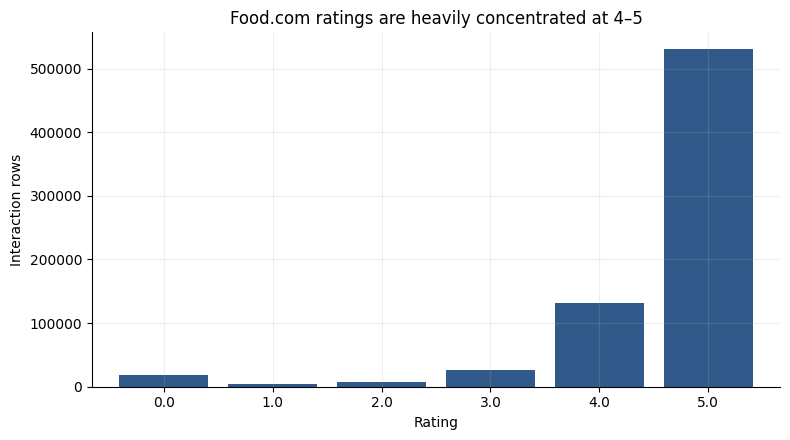

In [3]:
ratings = pd.Series({float(k): v for k, v in PROFILE['interactions']['rating_distribution'].items()}).sort_index()
ax = ratings.plot.bar(color='#315a8a', width=0.82)
ax.set_title('Food.com ratings are heavily concentrated at 4–5')
ax.set_xlabel('Rating')
ax.set_ylabel('Interaction rows')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


### 2. Token map

`PP_recipes.csv` uses the legacy OpenAI-GPT 40,478-token BPE vocabulary plus five recipe-specific control tokens. Names are wrapped with recipe start/end; instruction steps are wrapped with step start/end; padding is reserved but absent from the unpadded CSV sequences.


In [4]:
specials = pd.DataFrame([
    {'id': int(token_id), 'token': token, 'observed_count': PROFILE['tokens']['special_token_counts'].get(token_id, 0)}
    for token_id, token in PROFILE['tokens']['special_token_map'].items()
]).sort_values('id')
specials


,id,token,observed_count
0,40478,</s>,1603374
1,40479,</p>,0
2,40480,<R>,356530
3,40481,</R>,356530
4,40482,<s>,1603374


In [5]:
pd.DataFrame(PROFILE['tokens']['samples'])[['recipe_id', 'raw_name', 'name_token_ids', 'name_tokens', 'decoded_name']]


,recipe_id,raw_name,name_token_ids,name_tokens,decoded_name
0,424415,aromatic basmati rice rice cooker,"[40480, 37229, 2911, 1019, 249, 6878, 6878, 28...","[<R>, aromatic</w>, bas, mat, i</w>, rice</w>,...",aromatic basmati rice rice cooker
1,146223,pumpkin pie a la easy,"[40480, 18376, 7056, 246, 1531, 2032, 40481]","[<R>, pumpkin</w>, pie</w>, a</w>, la</w>, eas...",pumpkin pie a la easy
2,312329,cheesy tomato soup with potatoes,"[40480, 21044, 16954, 8294, 556, 10837, 40481]","[<R>, cheesy</w>, tomato</w>, soup</w>, with</...",cheesy tomato soup with potatoes
3,74301,mini tacos,"[40480, 10025, 31156, 40481]","[<R>, mini</w>, tacos</w>, </R>]",mini tacos
4,76272,rosemary s hanky panky s,"[40480, 17841, 252, 782, 2373, 1641, 2373, 252...","[<R>, rosemary</w>, s</w>, han, ky</w>, pan, k...",rosemary s hanky panky s


## Results

### 3. Split validity

The supplied generation splits have **zero train overlap** for validation and test recipe IDs. They are valid for the paper’s held-out recipe generation task, but invalid for evaluating collaborative item vectors. The replacement chronological split retains 91.0% warm-item validation coverage and 90.5% warm-item test coverage; the remaining cold items must use content/popularity fallback.


In [6]:
pd.DataFrame([
    {'check': 'Supplied train-validation item overlap', 'value': PROFILE['interactions']['item_overlap_across_splits']['train_validation']},
    {'check': 'Supplied train-test item overlap', 'value': PROFILE['interactions']['item_overlap_across_splits']['train_test']},
    {'check': 'Chronological validation warm-item coverage', 'value': f"{CF_SPLIT['validation_warm_item_rate']:.1%}"},
    {'check': 'Chronological test warm-item coverage', 'value': f"{CF_SPLIT['test_warm_item_rate']:.1%}"},
])


,check,value
0,Supplied train-validation item overlap,0
1,Supplied train-test item overlap,0
2,Chronological validation warm-item coverage,91.0%
3,Chronological test warm-item coverage,90.5%


### 4. Model comparison


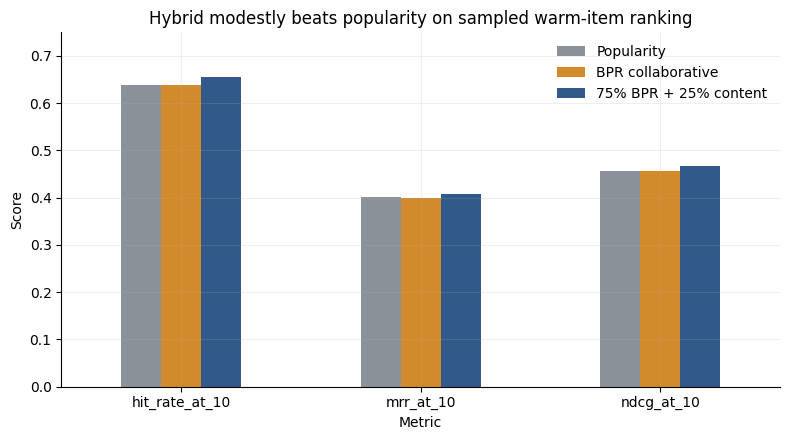

,Popularity,BPR collaborative,75% BPR + 25% content
hit_rate_at_10,0.6393,0.6375,0.6547
mrr_at_10,0.4006,0.3990,0.4085
ndcg_at_10,0.4573,0.4557,0.4670


In [7]:
selected = ['popularity', 'bpr', 'hybrid_bpr_75_content_25']
labels = {'popularity': 'Popularity', 'bpr': 'BPR collaborative', 'hybrid_bpr_75_content_25': '75% BPR + 25% content'}
metrics = ['hit_rate_at_10', 'mrr_at_10', 'ndcg_at_10']
comparison = pd.DataFrame({labels[name]: {metric: HYBRID['overall'][name][metric] for metric in metrics} for name in selected})
ax = comparison.plot.bar(color=['#8b9199', '#d28b2c', '#315a8a'])
ax.set_title('Hybrid modestly beats popularity on sampled warm-item ranking')
ax.set_xlabel('Metric')
ax.set_ylabel('Score')
ax.set_ylim(0, 0.75)
ax.tick_params(axis='x', rotation=0)
ax.legend(frameon=False, loc='upper right')
plt.tight_layout()
plt.show()
comparison.round(4)


## Takeaways

- **Use a hybrid, not CF alone.** Pure BPR is roughly tied with popularity overall. Adding a smaller ingredient-profile score gives the best tested result and provides a cold-start path.
- **Keep hard constraints deterministic.** Diet, allergy/exclusion, and time filters should run before the learned ranker; neither BPR nor text embeddings should be trusted as a safety filter.
- **Route by data availability.** Known user + warm item: 75% collaborative / 25% content. Unknown user or cold item: content + popularity.
- **Do not use the supplied validation/test files for CF evaluation.** They intentionally hold out recipes, so item latent factors cannot be learned.
- **Treat metrics as directional.** The sampled-negative protocol and historical Food.com population differ from Remymy traffic. A production decision needs logged impressions plus save/cook outcomes and full-candidate replay.

### Reproduce

Run `prepare_cf_splits.py`, then `train.py --objective bpr`, then `evaluate_hybrid.py`; exact source and artifact paths are documented in the model README.
